In [ ]:
import sys, os
sys.path.insert(0, os.path.abspath('..'))
from plot_config import COLORS, FIG_W_SINGLE, FIG_W_DOUBLE, set_font_size
GRID = False
FONT_SIZE = 18
LEGEND_FONT_SIZE = FONT_SIZE * 0.75  # change to resize legend text only
set_font_size(FONT_SIZE, LEGEND_FONT_SIZE)

## Procedure

1. Set up the load cell and wrap the string.
2. Set the config to use a tanh spring:

```
component=VirtualComponent(
    spring=TanhSpring(15.0, 1.5),
    damper=LinearDamper(1.5),
    s_param=1.0,
    name="lin_seg3",
),
goal=go_x_y,
```

3. `python3 Sequential_jump_tests.py`

# Tanh vs Linear Spring — Saturation Comparison

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

F_MAX = 1.33                # tanh saturation limit [N]
VIRTUAL_FORCE_YMAX = 1.4    # [N] fixed y-axis upper bound for the virtual-force panel
K_RETURN = 66.667    # snap-back stiffness to exclude
SS_FRAC = 0.40       # fraction (tail) of each window used for steady-state
G_TO_N = 9.80665e-3  # load cell outputs grams → convert to Newtons

files = {
    "Tanh (Fmax=1.33)": "outputs/tanh_spring/tanh_k10.npz",
    "Linear":           "outputs/tanh_spring/linear_k10.npz",
}
colors = {"Tanh (Fmax=1.33)": COLORS[1], "Linear": COLORS[0]}

# Darker, higher-contrast pair for the dual-axis virtual-vs-measured plot below
COLOR_VIRTUAL  = '#2C4A6B'   # deep navy -- virtual (model) force
COLOR_MEASURED = '#8B2E3F'   # deep wine red -- measured (load cell) force


def extract_windows(fn):
    """Return per-target hold windows, excluding the snap-back phases."""
    d = np.load(fn, allow_pickle=True)
    t      = d["t"]
    k      = d["k_params"][:, 0]
    goalx  = d["goal"][:, 0, 0]
    posx   = d["comp_pos"][:, 0, 0]
    fx     = d["f_virtual"][:, 0]
    fmag   = np.linalg.norm(d["f_virtual"], axis=1)
    force  = d["force"] * G_TO_N              # load cell: grams → Newtons

    # mask = test phases (anything that is NOT the snap-back stiffness)
    mask = ~np.isclose(k, K_RETURN)
    edges = np.diff(mask.astype(int))
    starts = np.where(edges == 1)[0] + 1
    ends   = np.where(edges == -1)[0] + 1
    if mask[0]:  starts = np.r_[0, starts]
    if mask[-1]: ends   = np.r_[ends, len(mask)]

    wins = []
    for s, e in zip(starts, ends):
        if e - s < 10:
            continue
        target = round(np.median(goalx[s:e]) / 0.05) * 0.05   # snap to 5cm grid
        if abs(target) < 1e-6:
            continue
        tail = slice(s + int((1 - SS_FRAC) * (e - s)), e)
        wins.append(dict(
            target=target,
            t=t[s:e] - t[s],          # time since jump
            goalx=goalx[s:e],
            posx=posx[s:e],
            fx=fx[s:e],
            fmag=fmag[s:e],
            force=force[s:e],                         # measured shear force [N]
            fx_ss=np.mean(fx[tail]),
            posx_ss=np.mean(posx[tail]),
            fmag_ss=np.mean(fmag[tail]),
            force_ss=np.mean(np.abs(force[tail])),    # steady-state measured force [N]
        ))
    wins.sort(key=lambda w: -w["target"])   # -0.05 first ... -0.50 last
    return wins


data = {name: extract_windows(fn) for name, fn in files.items()}
for name, wins in data.items():
    print(f"{name}: {len(wins)} test windows  "
          f"(targets {wins[0]['target']:.2f} … {wins[-1]['target']:.2f} m)")

## 1. Virtual vs. Measured force — Tanh

The controller's **virtual force** (what the model commands) is compared against the
**measured shear force** from the load cell. The two live on very different scales
(virtual ≈ N, measured ≈ tens of N due to string tension / mechanical advantage), so
each uses its own y-axis. The key point is the **shape**: both the commanded and the
physically measured force **saturate together** as displacement grows.

In [ ]:
def plot_virtual_vs_real(name):
    wins = data[name]
    disp     = np.array([abs(w["target"]) for w in wins]) * 100
    f_virt   = np.array([abs(w["fx_ss"]) for w in wins])
    f_real   = np.array([w["force_ss"] for w in wins])

    fig, ax1 = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.6))

    ax1.plot(disp, f_virt, "o-", color=COLOR_VIRTUAL, linewidth=2.5,
             markersize=9, markeredgecolor="black", markeredgewidth=1.2)
    ax1.set_xlabel("Commanded displacement (cm)")
    ax1.set_ylabel("Virtual force (N)", color=COLOR_VIRTUAL)
    ax1.tick_params(axis="y", labelcolor=COLOR_VIRTUAL)
    ax1.set_xlim(0, None)
    ax1.set_ylim(0, VIRTUAL_FORCE_YMAX)
    if "Tanh" in name:
        ax1.axhline(F_MAX, color=COLOR_VIRTUAL, linestyle="--", linewidth=1.5, alpha=0.7)
        ax1.text(disp.max() * 0.03, F_MAX - 0.05, rf'$F_{{max}} = {F_MAX:.1f}$',
                 ha='left', va='top', color=COLOR_VIRTUAL, fontsize=LEGEND_FONT_SIZE)

    ax2 = ax1.twinx()
    ax2.plot(disp, f_real, "s-", color=COLOR_MEASURED, linewidth=2.5,
             markersize=9, markeredgecolor="black", markeredgewidth=1.2)
    ax2.set_ylabel("Measured force (N)", color=COLOR_MEASURED)
    ax2.tick_params(axis="y", labelcolor=COLOR_MEASURED)
    ax2.set_ylim(0, None)

    ax1.grid(GRID)
    plt.tight_layout()
    slug = name.lower().replace(" ", "_").replace("(", "").replace(")", "").replace("=", "").replace(".", "")
    plt.savefig(os.path.join('outputs', 'tanh_spring', f'virtual_vs_real_{slug}.pdf'))
    plt.show()


plot_virtual_vs_real("Tanh (Fmax=1.33)")
print("→ Virtual force caps at F_max; measured shear force plateaus around ~0.71 N.")

## 2. Measured shear force — Tanh vs. Linear

The decisive real-world result: both measured on the **same load cell, same scale**.
The tanh spring's physical force **plateaus (~0.71 N)** while the linear spring's force
**keeps rising (~0.94 N and climbing)** — the saturation designed into the virtual
model is genuinely realized in hardware.

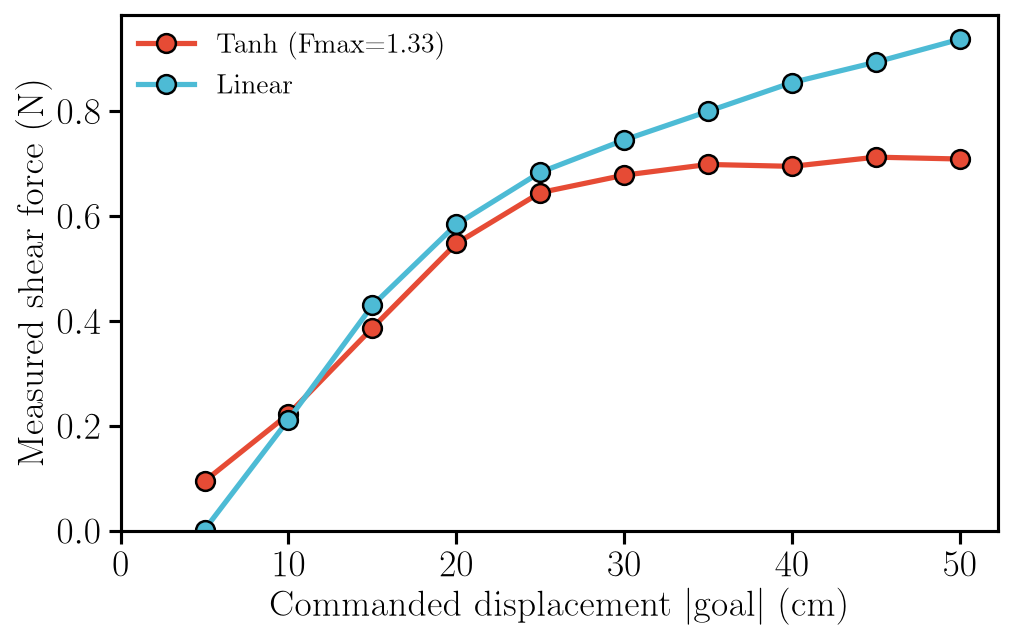

→ Physical proof: tanh shear force plateaus; linear shear force keeps growing.


In [4]:
fig, ax = plt.subplots(figsize=(FIG_W_DOUBLE, FIG_W_DOUBLE * 0.65))

for name, wins in data.items():
    disp   = np.array([abs(w["target"]) for w in wins]) * 100
    f_real = np.array([w["force_ss"] for w in wins])
    ax.plot(disp, f_real, "o-", color=colors[name], linewidth=2.5,
            markersize=9, markeredgecolor="black", markeredgewidth=1.2, label=name)

ax.set_xlabel("Commanded displacement |goal|  (cm)")
ax.set_ylabel("Measured shear force  (N)")
ax.set_xlim(0, None)
ax.set_ylim(0, None)
ax.grid(GRID)
ax.legend(loc="upper left")
plt.tight_layout()
plt.savefig(os.path.join('outputs', 'tanh_spring', 'measured_force_vs_displacement.pdf'))
plt.show()

print("→ Physical proof: tanh shear force plateaus; linear shear force keeps growing.")